# Team 4 — Reverse-Engineering Competition Evaluator

This notebook is designed to be run in **Google Colab**. Run the cells from top to bottom.

It will:

1. Ask you to upload the original `spike_data.npz` and the other teams' `team_<ID>_reconstruction.npz` files.
2. Create **Team 4's** standardized reconstruction file using the decomposition method from your existing notebook.
3. Validate each submission's required arrays and shapes.
4. Evaluate every available team (including Team 4) using the same seven heuristic metrics.
5. Save one JSON result and one diagnostic PNG per evaluated team, plus a CSV leaderboard and a ZIP of all outputs.

**Important interpretation:** the competition defines `reconstruction` as drift + spike signal, excluding a newly generated noise realization. Therefore, the evaluator compares that structured reconstruction with the recorded `raw_data`, which still contains noise. The score is a comparative heuristic, not a probability or a claim of biological accuracy. All teams are assessed by the same rule.

In [ ]:
# 1. Imports and configuration
import os
import re
import json
import glob
import zipfile
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import signal, stats

TEAM_ID = 4
REFERENCE_FILE = "spike_data.npz"
FS_FALLBACK = 1000.0       # Used only if the time vector cannot determine sampling rate
DRIFT_CUTOFF_HZ = 15.0
SPIKE_THRESHOLD_MAD = 4.0
MIN_SPIKE_DISTANCE_MS = 2.0
WIN_PRE = 4
WIN_POST = 16

OUTPUT_DIR = "team4_evaluation_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Configuration ready. Team ID:", TEAM_ID)


Configuration ready. Team ID: 4


## 2. Upload the data files

Select `spike_data.npz` and all available team submission files in the same upload dialog. The other teams' files should follow the required naming convention, for example `team_3_reconstruction.npz`.

If the files are already in the Colab working directory (or mounted Drive folder), you can skip the upload cell and set `DATA_DIR` in the next cell to their folder.

In [ ]:
# Upload files from your computer into the Colab working directory.
# You can select multiple .npz files at once.
from google.colab import files

uploaded = files.upload()
print("\nUploaded:", list(uploaded.keys()))


Saving team_3_reconstruction.npz to team_3_reconstruction (1).npz

Uploaded: ['team_3_reconstruction (1).npz']


In [ ]:
# 3. Set the folder containing the input files
# Leave "." if you used the upload cell above.
# If using Google Drive, mount Drive first and set DATA_DIR to the folder path.
DATA_DIR = "."

reference_path = os.path.join(DATA_DIR, REFERENCE_FILE)
if not os.path.isfile(reference_path):
    raise FileNotFoundError(
        f"Could not find {REFERENCE_FILE!r} in {DATA_DIR!r}. "
        "Upload the original file or correct DATA_DIR."
    )

ref = np.load(reference_path, allow_pickle=False)
required_ref = {"t", "raw_data"}
missing_ref = required_ref - set(ref.files)
if missing_ref:
    raise ValueError(f"Reference file is missing required arrays: {sorted(missing_ref)}")

t_ref = np.asarray(ref["t"]).ravel().astype(float)
raw_ref = np.asarray(ref["raw_data"]).ravel().astype(float)

if len(t_ref) != len(raw_ref):
    raise ValueError("Reference time vector and raw_data have different lengths.")
if len(t_ref) < 100:
    raise ValueError("Reference recording is unexpectedly short.")

dt_values = np.diff(t_ref)
dt = float(np.median(dt_values))
fs = 1.0 / dt if dt > 0 else FS_FALLBACK
if not np.isfinite(fs) or fs <= 0:
    fs = FS_FALLBACK

print(f"Reference loaded: {len(raw_ref)} samples")
print(f"Duration: {t_ref[-1] - t_ref[0]:.4f} s")
print(f"Estimated sampling rate: {fs:.2f} Hz")
print("Reference arrays:", ref.files)


Reference loaded: 10000 samples
Duration: 9.9990 s
Estimated sampling rate: 1000.00 Hz
Reference arrays: ['t', 'raw_data']


## 4. Create Team 4's standardized reconstruction

The required `reconstruction` is **drift + spike_signal**, not drift + spikes + a newly generated noise realization. The `noise` array is retained as the residual for the submission schema, but it is deliberately excluded from `reconstruction`.

This cell writes `team_4_reconstruction.npz` with all six required variables.

In [ ]:
# 4. Generate Team 4's reconstruction from the original recording

nyquist = fs / 2.0
cutoff = min(DRIFT_CUTOFF_HZ, nyquist * 0.8)
if cutoff <= 0:
    raise ValueError("Invalid sampling rate / drift cutoff.")

b, a = signal.butter(3, cutoff / nyquist, btype="low")
drift = signal.filtfilt(b, a, raw_ref)
residual = raw_ref - drift

mad_noise = np.median(np.abs(residual - np.median(residual))) / 0.6745
if not np.isfinite(mad_noise) or mad_noise <= 0:
    mad_noise = float(np.std(residual) + 1e-12)

polarity = 1.0 if stats.skew(residual, nan_policy="omit") >= 0 else -1.0
aligned_residual = polarity * residual

peak_distance = max(1, int(round((MIN_SPIKE_DISTANCE_MS / 1000.0) * fs)))
peaks, peak_properties = signal.find_peaks(
    aligned_residual,
    height=SPIKE_THRESHOLD_MAD * mad_noise,
    distance=peak_distance
)

waveforms = []
for p in peaks:
    start, end = p - WIN_PRE, p + WIN_POST
    if start >= 0 and end <= len(raw_ref):
        waveforms.append(aligned_residual[start:end])

template_length = WIN_PRE + WIN_POST
if waveforms:
    mean_template = np.mean(waveforms, axis=0)
    mean_template = mean_template / (np.max(np.abs(mean_template)) + 1e-12)
else:
    mean_template = np.zeros(template_length, dtype=float)

spike_signal = np.zeros_like(raw_ref, dtype=float)
valid_peaks = []
for p in peaks:
    start, end = p - WIN_PRE, p + WIN_POST
    if start >= 0 and end <= len(raw_ref):
        amplitude = aligned_residual[p]
        spike_signal[start:end] += polarity * amplitude * mean_template
        valid_peaks.append(int(p))

spike_indices = np.asarray(valid_peaks, dtype=np.int32)
reconstruction = drift + spike_signal
noise = raw_ref - reconstruction

team4_file = f"team_{TEAM_ID}_reconstruction.npz"
np.savez(
    team4_file,
    t=t_ref.astype(np.float64),
    drift=drift.astype(np.float64),
    spike_signal=spike_signal.astype(np.float64),
    noise=noise.astype(np.float64),
    reconstruction=reconstruction.astype(np.float64),
    spike_indices=spike_indices
)

print(f"Saved {team4_file}")
print("Array shapes:")
for key, value in {
    "t": t_ref, "drift": drift, "spike_signal": spike_signal,
    "noise": noise, "reconstruction": reconstruction,
    "spike_indices": spike_indices
}.items():
    print(f"  {key:16s} {value.shape}")
print(f"Detected spikes: {len(spike_indices)}")


Saved team_4_reconstruction.npz
Array shapes:
  t                (10000,)
  drift            (10000,)
  spike_signal     (10000,)
  noise            (10000,)
  reconstruction   (10000,)
  spike_indices    (47,)
Detected spikes: 47


## 5. Evaluation functions

The evaluator uses the required `reconstruction` array for candidate submissions. It does not substitute `noise`, `spike_signal`, or another component when `reconstruction` is missing.

Validity checks cover required keys, one-dimensional arrays, matching lengths, finite values, and time-vector agreement. A malformed submission is recorded as invalid rather than silently scored.

The seven equally weighted heuristic dimensions are:
- standard-deviation match
- amplitude-distribution Wasserstein match
- Welch PSD cosine similarity
- detected firing-rate match
- mean detected peak-amplitude match
- skewness/kurtosis match
- short-lag autocorrelation-shape match

The sampling rate is inferred from the reference time vector.

In [ ]:
# 5. Evaluation functions

def _safe_similarity_score(reference_value, candidate_value, scale):
    return float(100.0 * np.exp(-abs(reference_value - candidate_value) / (abs(scale) + 1e-12)))

def _detect_positive_peaks(x, fs, threshold_mad=3.5):
    x = np.asarray(x, dtype=float)
    centered = x - np.median(x)
    noise_sd = np.median(np.abs(centered)) / 0.6745
    if not np.isfinite(noise_sd) or noise_sd <= 0:
        noise_sd = np.std(x) + 1e-12
    distance = max(1, int(round(0.002 * fs)))
    peaks, _ = signal.find_peaks(
        x,
        height=np.median(x) + threshold_mad * noise_sd,
        distance=distance
    )
    return peaks

def _short_lag_acf(x, max_lag):
    x = np.asarray(x, dtype=float)
    x = x - np.mean(x)
    denom = np.dot(x, x)
    if denom <= 1e-15:
        return np.zeros(max_lag + 1)
    # FFT-based autocorrelation, normalized at lag zero
    corr = signal.fftconvolve(x, x[::-1], mode="full")
    center = len(x) - 1
    acf = corr[center:center + max_lag + 1]
    return acf / (acf[0] + 1e-12)

def evaluate_submission(reference_path, candidate_path, team_name, make_plot=True):
    result = {
        "team": team_name,
        "file": os.path.basename(candidate_path),
        "validity": "FAIL",
        "validation_errors": [],
        "final_score": None,
        "metrics": {}
    }

    try:
        ref_data = np.load(reference_path, allow_pickle=False)
        cand_data = np.load(candidate_path, allow_pickle=False)

        required_ref_keys = {"t", "raw_data"}
        required_candidate_keys = {
            "t", "drift", "spike_signal", "noise", "reconstruction", "spike_indices"
        }

        missing_ref = required_ref_keys - set(ref_data.files)
        missing_candidate = required_candidate_keys - set(cand_data.files)

        if missing_ref:
            result["validation_errors"].append(f"Reference missing keys: {sorted(missing_ref)}")
        if missing_candidate:
            result["validation_errors"].append(f"Candidate missing keys: {sorted(missing_candidate)}")

        if missing_ref or missing_candidate:
            return result

        t0 = np.asarray(ref_data["t"]).ravel().astype(float)
        x = np.asarray(ref_data["raw_data"]).ravel().astype(float)
        tc = np.asarray(cand_data["t"]).ravel().astype(float)
        y = np.asarray(cand_data["reconstruction"]).ravel().astype(float)

        component_names = ["drift", "spike_signal", "noise"]
        components = {
            name: np.asarray(cand_data[name]).ravel().astype(float)
            for name in component_names
        }
        spike_indices_candidate = np.asarray(cand_data["spike_indices"]).ravel()

        if not (len(t0) == len(x)):
            result["validation_errors"].append("Reference t and raw_data lengths differ.")
        if not (len(tc) == len(y)):
            result["validation_errors"].append("Candidate t and reconstruction lengths differ.")
        for name, arr in components.items():
            if len(arr) != len(y):
                result["validation_errors"].append(f"Candidate {name} length differs from reconstruction.")
        if len(t0) != len(tc):
            result["validation_errors"].append("Candidate and reference sample counts differ.")
        elif not np.allclose(t0, tc, rtol=1e-5, atol=1e-8):
            result["validation_errors"].append("Candidate time vector does not match reference time vector.")
        if not np.all(np.isfinite(x)) or not np.all(np.isfinite(y)):
            result["validation_errors"].append("Reference or reconstruction contains NaN/Inf values.")
        if len(spike_indices_candidate) and (
            np.any(spike_indices_candidate < 0) or np.any(spike_indices_candidate >= len(y))
        ):
            result["validation_errors"].append("spike_indices contains out-of-range indices.")

        # Check the required definition: reconstruction = drift + spike_signal
        component_sum_error = float(np.max(np.abs(y - (components["drift"] + components["spike_signal"]))))
        result["metrics"]["max_reconstruction_sum_error"] = component_sum_error
        if component_sum_error > 1e-5:
            result["validation_errors"].append(
                "reconstruction is not equal to drift + spike_signal within tolerance."
            )

        if result["validation_errors"]:
            return result

        # Use sampling rate from the reference time vector.
        local_dt = float(np.median(np.diff(t0)))
        local_fs = 1.0 / local_dt

        # Metric 1: global standard deviation
        std_ref, std_cand = float(np.std(x)), float(np.std(y))
        std_score = _safe_similarity_score(std_ref, std_cand, std_ref)

        # Metric 2: Wasserstein distance
        w_dist = float(stats.wasserstein_distance(x, y))
        wd_score = float(100.0 * np.exp(-w_dist / (std_ref + 1e-12)))

        # Metric 3: PSD shape cosine similarity
        nperseg = min(len(x), len(y), max(8, int(round(local_fs))))
        _, psd_ref = signal.welch(x, fs=local_fs, nperseg=nperseg)
        _, psd_cand = signal.welch(y, fs=local_fs, nperseg=nperseg)
        psd_cos = float(
            np.dot(psd_ref, psd_cand) /
            (np.linalg.norm(psd_ref) * np.linalg.norm(psd_cand) + 1e-12)
        )
        psd_score = 100.0 * float(np.clip(psd_cos, 0.0, 1.0))

        # Metric 4: positive-going peak rate (same detector settings for both)
        peaks_ref = _detect_positive_peaks(x, local_fs)
        peaks_cand = _detect_positive_peaks(y, local_fs)
        duration_ref = len(x) / local_fs
        duration_cand = len(y) / local_fs
        rate_ref = len(peaks_ref) / duration_ref
        rate_cand = len(peaks_cand) / duration_cand
        rate_score = _safe_similarity_score(rate_ref, rate_cand, rate_ref)

        # Metric 5: mean peak amplitude
        amp_ref = float(np.mean(x[peaks_ref])) if len(peaks_ref) else 0.0
        amp_cand = float(np.mean(y[peaks_cand])) if len(peaks_cand) else 0.0
        amp_score = _safe_similarity_score(amp_ref, amp_cand, amp_ref)

        # Metric 6: skewness and excess kurtosis
        skew_ref, skew_cand = float(stats.skew(x)), float(stats.skew(y))
        kurt_ref, kurt_cand = float(stats.kurtosis(x)), float(stats.kurtosis(y))
        skew_score = _safe_similarity_score(skew_ref, skew_cand, skew_ref)
        kurt_score = _safe_similarity_score(kurt_ref, kurt_cand, kurt_ref)
        moments_score = 0.5 * (skew_score + kurt_score)

        # Metric 7: short-lag autocorrelation shape
        max_lag = min(int(round(0.25 * local_fs)), len(x) - 1, len(y) - 1)
        acf_ref = _short_lag_acf(x, max_lag)
        acf_cand = _short_lag_acf(y, max_lag)
        if np.std(acf_ref) < 1e-12 or np.std(acf_cand) < 1e-12:
            acf_corr = 1.0 if np.allclose(acf_ref, acf_cand) else 0.0
        else:
            acf_corr = float(np.corrcoef(acf_ref, acf_cand)[0, 1])
        if not np.isfinite(acf_corr):
            acf_corr = 0.0
        acf_score = 100.0 * float(np.clip(acf_corr, 0.0, 1.0))

        metric_scores = {
            "standard_deviation": std_score,
            "wasserstein_distribution": wd_score,
            "psd_shape": psd_score,
            "firing_rate": rate_score,
            "mean_peak_amplitude": amp_score,
            "statistical_moments": moments_score,
            "autocorrelation": acf_score
        }
        final_score = float(np.mean(list(metric_scores.values())))

        result["validity"] = "PASS"
        result["final_score"] = round(final_score, 2)
        result["metrics"].update({
            "reference_std": std_ref,
            "reconstruction_std": std_cand,
            "wasserstein_distance": w_dist,
            "psd_cosine_similarity": psd_cos,
            "reference_detected_spike_rate_hz": rate_ref,
            "candidate_detected_spike_rate_hz": rate_cand,
            "reference_mean_peak_amplitude": amp_ref,
            "candidate_mean_peak_amplitude": amp_cand,
            "reference_skewness": skew_ref,
            "candidate_skewness": skew_cand,
            "reference_excess_kurtosis": kurt_ref,
            "candidate_excess_kurtosis": kurt_cand,
            "acf_correlation": acf_corr,
            "metric_scores": {k: round(v, 4) for k, v in metric_scores.items()}
        })

        if make_plot:
            fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

            show_n = min(len(x), len(y), int(round(2.5 * local_fs)))
            axes[0].plot(t0[:show_n], x[:show_n], label="Original raw signal", lw=0.8)
            axes[0].plot(tc[:show_n], y[:show_n], label="Candidate reconstruction", lw=0.8, alpha=0.8)
            axes[0].set_title("First 2.5 seconds: overlay")
            axes[0].set_xlabel("Time (s)")
            axes[0].set_ylabel("Amplitude")
            axes[0].legend()
            axes[0].grid(alpha=0.3)

            axes[1].semilogy(*signal.welch(x, fs=local_fs, nperseg=nperseg), label="Original")
            axes[1].semilogy(*signal.welch(y, fs=local_fs, nperseg=nperseg), label="Reconstruction")
            axes[1].set_title("Power spectral density")
            axes[1].set_xlabel("Frequency (Hz)")
            axes[1].set_ylabel("Power / frequency")
            axes[1].legend()
            axes[1].grid(alpha=0.3, which="both")

            axes[2].hist(x, bins=150, density=True, histtype="step", cumulative=True, label="Original")
            axes[2].hist(y, bins=150, density=True, histtype="step", cumulative=True, label="Reconstruction")
            axes[2].set_title("Amplitude CDF")
            axes[2].set_xlabel("Amplitude")
            axes[2].set_ylabel("Cumulative probability")
            axes[2].legend()
            axes[2].grid(alpha=0.3)

            fig.suptitle(f"{team_name} — heuristic score: {final_score:.2f}%")
            fig.tight_layout()
            plot_path = os.path.join(OUTPUT_DIR, f"{team_name.lower().replace(' ', '_')}_diagnostics.png")
            fig.savefig(plot_path, dpi=160, bbox_inches="tight")
            plt.show()
            plt.close(fig)
            result["plot_file"] = plot_path

        return result

    except Exception as exc:
        result["validation_errors"].append(f"Evaluation exception: {type(exc).__name__}: {exc}")
        return result


## 6. Automatically find and evaluate every team file

The notebook scans `DATA_DIR` for `team_*_reconstruction.npz`, excludes any pre-existing Team 4 file, then adds the Team 4 file generated above. Team labels are taken from filenames. No guessed filenames are inserted.

If a team's file is missing required arrays or fails a validity check, its status and reason are saved in the results rather than crashing the whole run.

Files selected for evaluation:
  Team 3: ./team_3_reconstruction.npz
  Team 4: team_4_reconstruction.npz
  Team 7: ./team_7_reconstruction.npz

Evaluating Team 3: ./team_3_reconstruction.npz


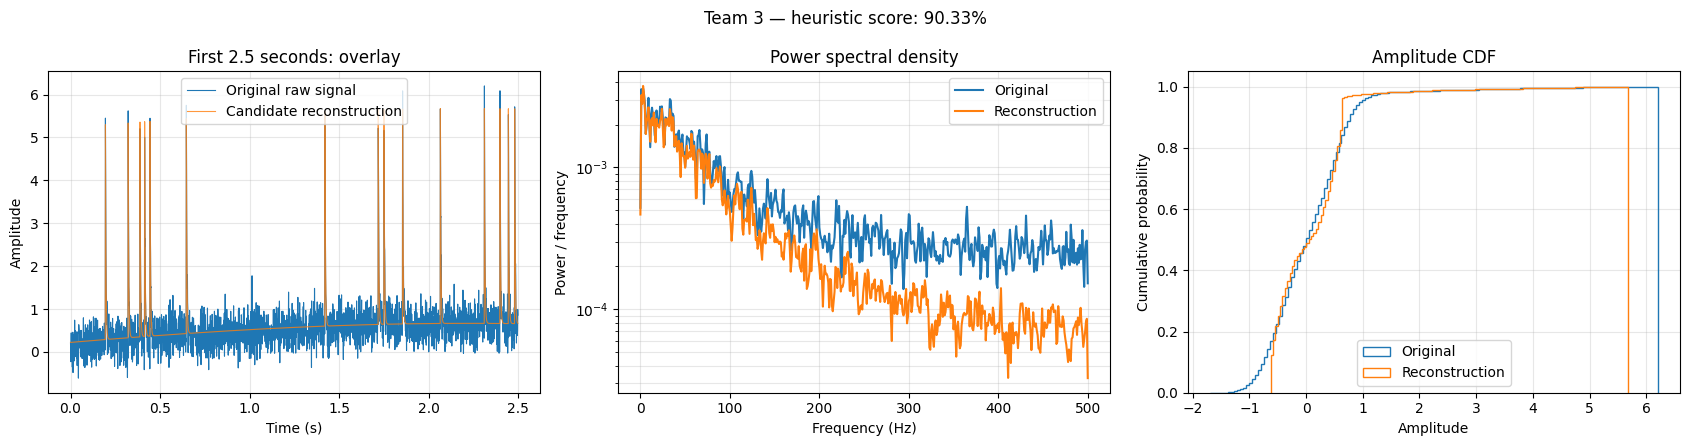

VALID — final heuristic score: 90.33%

Evaluating Team 4: team_4_reconstruction.npz


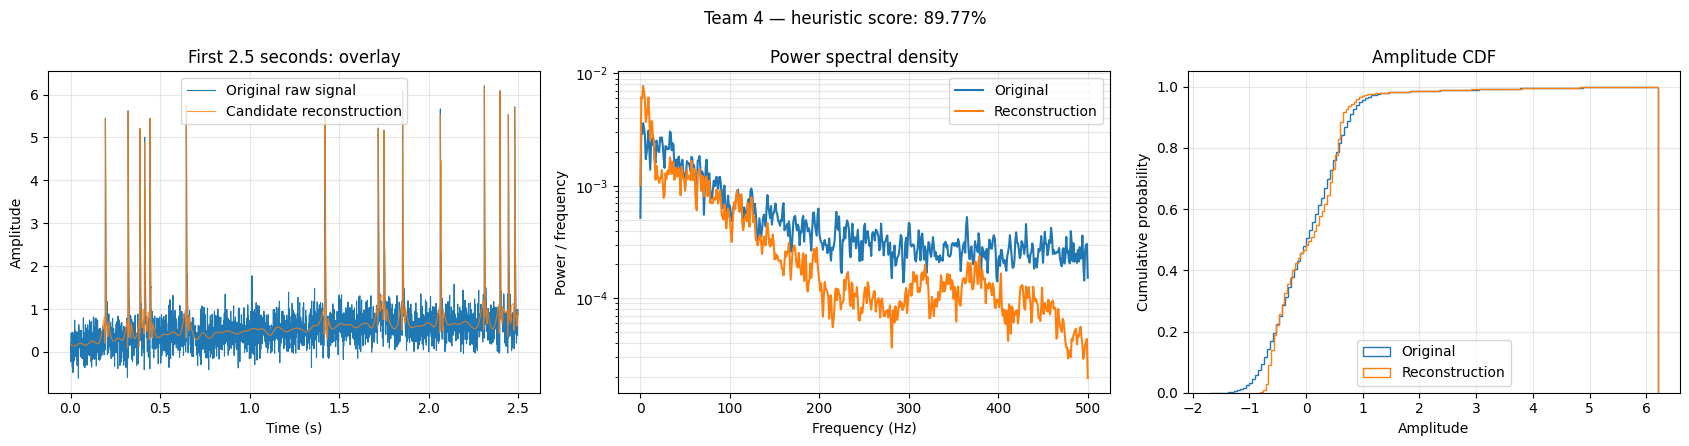

VALID — final heuristic score: 89.77%

Evaluating Team 7: ./team_7_reconstruction.npz


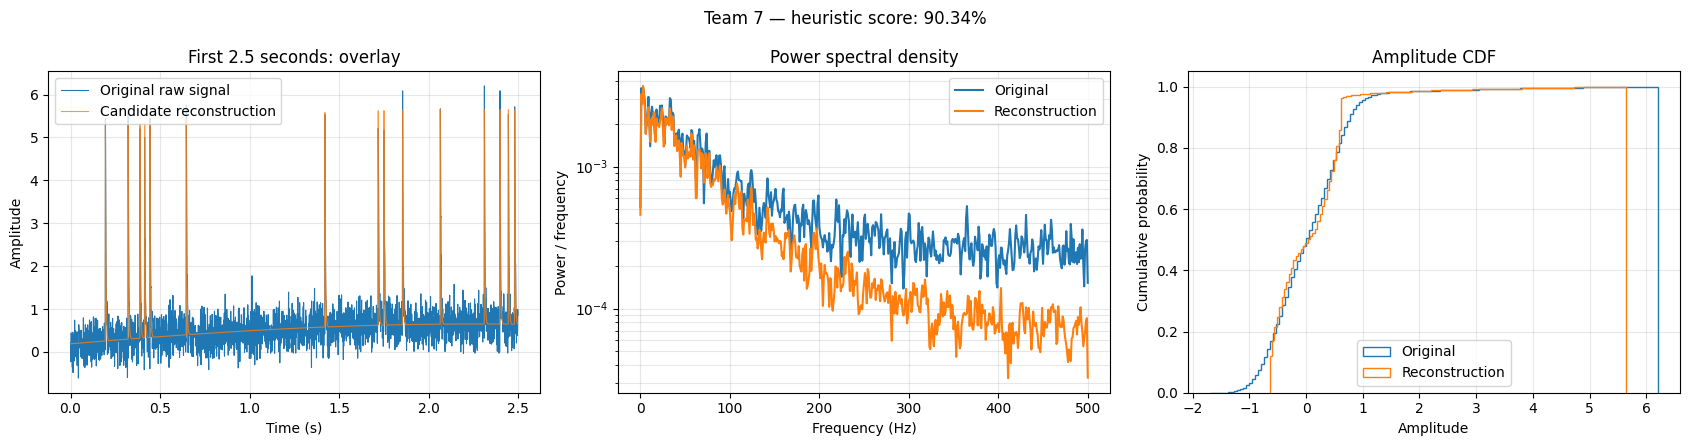

VALID — final heuristic score: 90.34%

Evaluation loop complete.


In [ ]:
# 6. Discover submissions and evaluate all teams, including Team 4

pattern = os.path.join(DATA_DIR, "team_*_reconstruction.npz")
discovered_files = sorted(glob.glob(pattern))

# Keep one entry per team ID; our freshly generated Team 4 file takes precedence.
team_files = {}
for path in discovered_files:
    match = re.search(r"team_(\d+)_reconstruction\.npz$", os.path.basename(path), re.IGNORECASE)
    if match:
        team_id = int(match.group(1))
        if team_id != TEAM_ID:
            team_files[team_id] = path

team_files[TEAM_ID] = team4_file

if not team_files:
    raise RuntimeError("No team reconstruction files found.")

print("Files selected for evaluation:")
for team_id, path in sorted(team_files.items()):
    print(f"  Team {team_id}: {path}")

all_results = []
for team_id, candidate_path in sorted(team_files.items()):
    team_name = f"Team {team_id}"
    print("\n" + "=" * 72)
    print(f"Evaluating {team_name}: {candidate_path}")

    result = evaluate_submission(
        reference_path=reference_path,
        candidate_path=candidate_path,
        team_name=team_name,
        make_plot=True
    )
    all_results.append(result)

    # Save an individual JSON result for every evaluated team, including invalid files.
    json_path = os.path.join(OUTPUT_DIR, f"team_{team_id}_result.json")
    with open(json_path, "w") as f:
        json.dump(result, f, indent=2, allow_nan=False)

    if result["validity"] == "PASS":
        print(f"VALID — final heuristic score: {result['final_score']:.2f}%")
    else:
        print("INVALID —", "; ".join(result["validation_errors"]))

print("\nEvaluation loop complete.")


## 7. Leaderboard and downloadable results

The leaderboard includes valid scores and clearly marks invalid submissions. It also saves a CSV summary and a ZIP containing all per-team JSON results and diagnostic plots.

In [ ]:
# 7. Build and save leaderboard
leaderboard_rows = []
for r in all_results:
    leaderboard_rows.append({
        "Team": r["team"],
        "File": r["file"],
        "Validity": r["validity"],
        "Final Score (%)": r["final_score"],
        "Validation Errors": " | ".join(r["validation_errors"])
    })

leaderboard = pd.DataFrame(leaderboard_rows)
leaderboard["_sort_score"] = leaderboard["Final Score (%)"].fillna(-1)
leaderboard = leaderboard.sort_values(
    by=["Validity", "_sort_score"],
    ascending=[True, False]
).drop(columns="_sort_score")

csv_path = os.path.join(OUTPUT_DIR, "competition_leaderboard.csv")
leaderboard.to_csv(csv_path, index=False)

display(leaderboard)

print("\nSaved leaderboard:", csv_path)


,Team,File,Validity,Final Score (%),Validation Errors
2,Team 7,team_7_reconstruction.npz,PASS,90.34,
0,Team 3,team_3_reconstruction.npz,PASS,90.33,
1,Team 4,team_4_reconstruction.npz,PASS,89.77,



Saved leaderboard: team4_evaluation_outputs/competition_leaderboard.csv


In [ ]:
# 8. Package all outputs into one ZIP and download it
zip_path = "team4_competition_evaluation_results.zip"

with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    # Team 4's standardized submission
    zf.write(team4_file, arcname=os.path.basename(team4_file))

    # Leaderboard and all per-team reports/plots
    for root, _, filenames in os.walk(OUTPUT_DIR):
        for filename in filenames:
            full_path = os.path.join(root, filename)
            arcname = os.path.relpath(full_path, ".")
            zf.write(full_path, arcname=arcname)

print("Created:", zip_path)
print("Contents include Team 4 submission, leaderboard, per-team JSON reports, and diagnostic PNGs.")

from google.colab import files
files.download(zip_path)


Created: team4_competition_evaluation_results.zip
Contents include Team 4 submission, leaderboard, per-team JSON reports, and diagnostic PNGs.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Notes on interpreting the scores

- **The score is a heuristic comparison**, not an official validated metric unless your instructor approves this exact scoring rule.
- Candidate `reconstruction` intentionally excludes noise per the competition instructions, while the reference `raw_data` includes the recorded noise. Some distribution and spectral metrics will therefore penalize candidates for not containing noise; that is a consequence of the required comparison, not necessarily a bad reconstruction.
- The peak detector counts positive-going peaks. If the recording's spikes are negative-going, the firing-rate and peak-amplitude metrics may be less meaningful. Interpret those dimensions with care.
- The notebook checks that `reconstruction ≈ drift + spike_signal`; it does not require `noise` to be added to reconstruction.
- The notebook uses the sampling rate inferred from `t`, rather than assuming 1000 Hz when a valid time vector is available.
- If your instructor specifies a different scoring formula, change the metric weights/formula consistently for every team before the in-class evaluation.